<a href="https://colab.research.google.com/github/pradityaputra888-lab/latihan-machine-learning/blob/main/pertemuan11/Bab11_DimReduction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 11 — Dimensionality Reduction: PCA, t-SNE, dan LDA

**Dataset:** Digits (Praktikum 11.1–11.7) dan Wine (Latihan 2) · **Isi notebook:** Praktikum 11.1–11.6 (kode modul), Latihan 1 (Praktikum 11.7), dan Latihan 2 (perbandingan PCA, t-SNE, LDA).

> Jalankan sel dari atas ke bawah secara berurutan. Sel t-SNE membutuhkan beberapa detik.

## 11.11 Implementasi Python

### Praktikum 11.1 Persiapan Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

print("Library berhasil dimuat.")

Library berhasil dimuat.


### Praktikum 11.2 Import Dataset

In [2]:
digits = load_digits()
X, y = digits.data, digits.target
print("Dimensi data asli:", X.shape)   # (1797, 64)

Dimensi data asli: (1797, 64)


### Praktikum 11.3 Preprocessing

In [3]:
X_scaled = StandardScaler().fit_transform(X)

### Praktikum 11.4 Training Model (PCA, t-SNE, LDA)

In [4]:
pca = PCA(n_components=0.90)            # pertahankan 90% variance
X_pca = pca.fit_transform(X_scaled)
print("Jumlah komponen untuk 90% variance:", pca.n_components_)

X_tsne = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X_scaled)

lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X_scaled, y)   # LDA memerlukan label y
print("Hasil: PCA", X_pca.shape, "| t-SNE", X_tsne.shape, "| LDA", X_lda.shape)

Jumlah komponen untuk 90% variance: 31
Hasil: PCA (1797, 31) | t-SNE (1797, 2) | LDA (1797, 2)


### Praktikum 11.5 Evaluasi

In [5]:
print("Explained variance ratio (5 komponen pertama):", np.round(pca.explained_variance_ratio_[:5], 3))
print("Total variance dijelaskan:", round(pca.explained_variance_ratio_.sum(), 3))

Explained variance ratio (5 komponen pertama): [0.12  0.096 0.084 0.065 0.049]
Total variance dijelaskan: 0.9


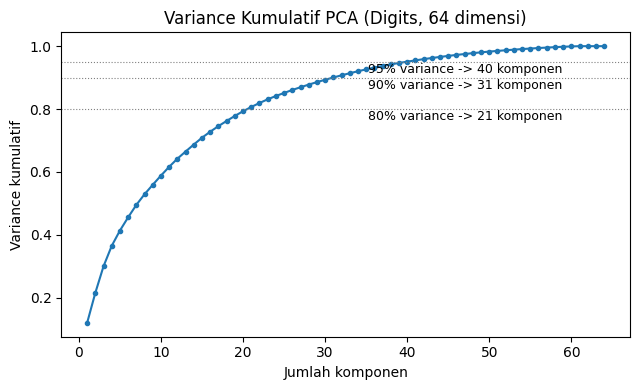

In [6]:
# Tambahan: scree plot / variance kumulatif untuk semua komponen
pca_penuh = PCA().fit(X_scaled)
kum = np.cumsum(pca_penuh.explained_variance_ratio_)
plt.figure(figsize=(6.5, 4))
plt.plot(range(1, len(kum) + 1), kum, "o-", ms=3)
for batas in [0.80, 0.90, 0.95]:
    n_perlu = int(np.argmax(kum >= batas)) + 1
    plt.axhline(batas, color="gray", ls=":", lw=0.8)
    plt.text(len(kum) * 0.55, batas - 0.035, f"{int(batas*100)}% variance -> {n_perlu} komponen", fontsize=9)
plt.xlabel("Jumlah komponen"); plt.ylabel("Variance kumulatif")
plt.title("Variance Kumulatif PCA (Digits, 64 dimensi)")
plt.tight_layout(); plt.show()

### Praktikum 11.6 Visualisasi
> Kode modul menampilkan PCA dan t-SNE; panel LDA ditambahkan karena `X_lda` sudah dihitung pada Praktikum 11.4.

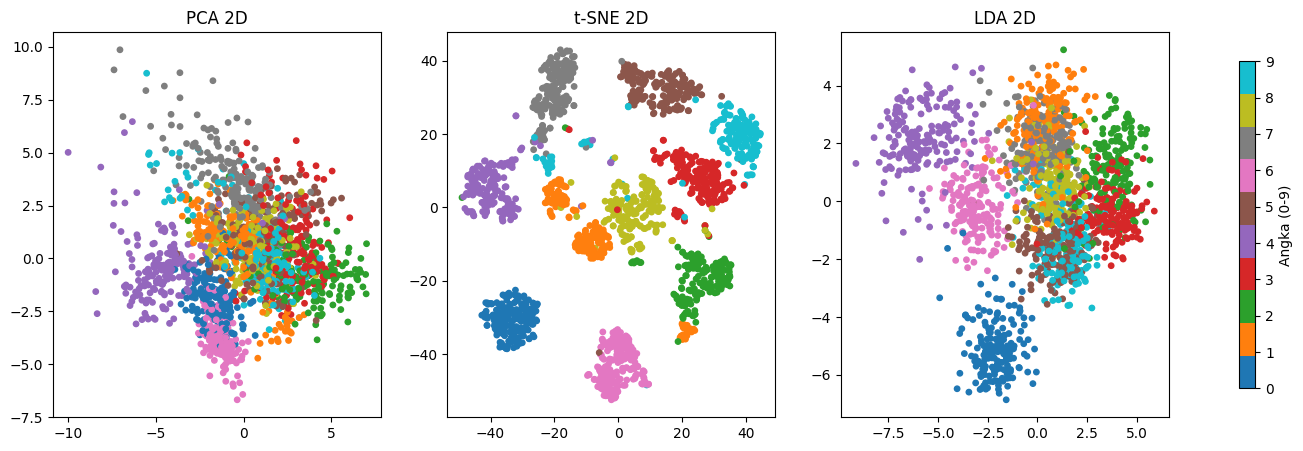

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, emb, judul in zip(axes, [X_pca[:, :2], X_tsne, X_lda], ["PCA 2D", "t-SNE 2D", "LDA 2D"]):
    sc = ax.scatter(emb[:, 0], emb[:, 1], c=y, cmap="tab10", s=15)
    ax.set_title(judul)
fig.colorbar(sc, ax=axes, label="Angka (0-9)", shrink=0.85)
plt.show()

### Interpretasi (Praktikum 11.1–11.6)
- **Reduksi dimensi:** untuk mempertahankan 90% variance, PCA memerlukan **31 dari 64 komponen** (berkurang 52%). Lima komponen pertama hanya menjelaskan 0,120, 0,096, 0,084, 0,065, dan 0,049 variance (total ≈ 0,41). Variance tersebar merata, tidak ada satu komponen yang dominan, karena informasi tiap digit tersebar di banyak piksel.
- **PCA 2D** (hanya ≈ 21,6% variance) tumpang tindih berat; hanya digit 0, 4, dan 6 yang relatif terpisah. Dua komponen tidak cukup untuk menangkap perbedaan 10 digit.
- **t-SNE 2D** menghasilkan **10 gugus yang tegas dan terpisah**, sesuai pernyataan modul bahwa t-SNE lebih tegas memisahkan cluster. Ia mempertahankan struktur tetangga lokal yang bersifat non-linear.
- **LDA 2D** (panel tambahan) memisahkan digit 0, 4, dan 6 dengan jelas, tetapi digit lain masih bertumpuk karena hanya 2 dari maksimal 9 sumbu diskriminan yang ditampilkan.
- **Kapan dipakai:** PCA cocok sebagai tahap *preprocessing* karena dapat diterapkan ke data baru. t-SNE hanya untuk eksplorasi visual: ia tidak punya `transform()` untuk data baru, jarak antar gugus dan ukuran gugus tidak bermakna kuantitatif, dan hasilnya bergantung pada `perplexity` dan *seed*.

---
## 11.12 Latihan Praktikum

### Latihan 1 — Kompresi Dimensi dengan PCA (Praktikum 11.7)
**Tujuan:** menentukan jumlah komponen PCA yang optimal dan mengevaluasi dampaknya terhadap performa klasifikasi.

> **Catatan metodologi:** kode modul men-*scale* seluruh data sebelum dibagi, sehingga ada kebocoran informasi yang sangat kecil dari data uji ke *scaler*. Untuk keperluan latihan ini dampaknya diabaikan, tetapi pada proyek sebenarnya gunakan `Pipeline` seperti di Bab 4. **PCA sendiri sudah di-fit hanya pada data latih.**

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import time

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

hasil_pca = []
for n_comp in [0.80, 0.90, 0.95, None]:
    pca_i = PCA(n_components=n_comp) if n_comp else PCA()
    X_train_p = pca_i.fit_transform(X_train)
    X_test_p = pca_i.transform(X_test)
    t0 = time.time()
    model = LogisticRegression(max_iter=2000).fit(X_train_p, y_train)
    waktu = time.time() - t0
    acc = accuracy_score(y_test, model.predict(X_test_p))
    print(f"n_components={n_comp}: dimensi={X_train_p.shape[1]}, akurasi={acc:.3f}")
    hasil_pca.append({"n_components": n_comp if n_comp else "semua (PCA())",
                      "Dimensi": X_train_p.shape[1],
                      "Akurasi": round(acc, 3),
                      "Waktu latih (detik)": round(waktu, 3)})

pd.DataFrame(hasil_pca)

n_components=0.8: dimensi=21, akurasi=0.947
n_components=0.9: dimensi=31, akurasi=0.958
n_components=0.95: dimensi=40, akurasi=0.964
n_components=None: dimensi=64, akurasi=0.972


,n_components,Dimensi,Akurasi,Waktu latih (detik)
0,0.8,21,0.947,0.197
1,0.9,31,0.958,0.166
2,0.95,40,0.964,0.475
3,semua (PCA()),64,0.972,0.616


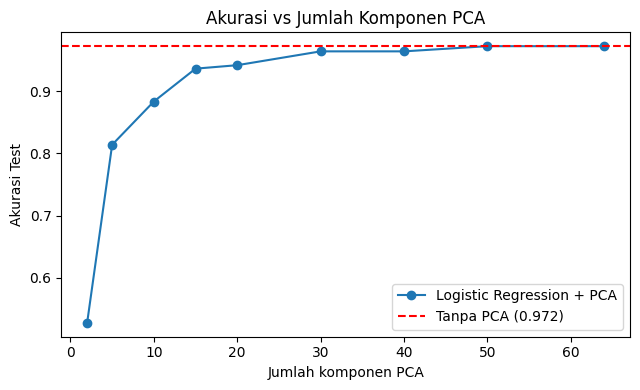

{2: 0.528, 5: 0.814, 10: 0.883, 15: 0.936, 20: 0.942, 30: 0.964, 40: 0.964, 50: 0.972, 64: 0.972}


In [9]:
# Tambahan: akurasi untuk setiap jumlah komponen 5-64 + pembanding tanpa PCA
jumlah = [2, 5, 10, 15, 20, 30, 40, 50, 64]
akurasi = []
for k in jumlah:
    p = PCA(n_components=k).fit(X_train)
    m = LogisticRegression(max_iter=2000).fit(p.transform(X_train), y_train)
    akurasi.append(accuracy_score(y_test, m.predict(p.transform(X_test))))
baseline = accuracy_score(y_test, LogisticRegression(max_iter=2000).fit(X_train, y_train).predict(X_test))

plt.figure(figsize=(6.5, 4))
plt.plot(jumlah, akurasi, "o-", label="Logistic Regression + PCA")
plt.axhline(baseline, color="red", ls="--", label=f"Tanpa PCA ({baseline:.3f})")
plt.xlabel("Jumlah komponen PCA"); plt.ylabel("Akurasi Test"); plt.legend()
plt.title("Akurasi vs Jumlah Komponen PCA")
plt.tight_layout(); plt.show()
print({k: round(float(a), 3) for k, a in zip(jumlah, akurasi)})

**Analisis Latihan 1:**

| n_components | Dimensi | Akurasi Test |
|---|---|---|
| 0,80 | 21 | 0,947 |
| 0,90 | 31 | 0,958 |
| 0,95 | 40 | 0,964 |
| semua (PCA()) | 64 | 0,972 |

- **Hubungan komponen–akurasi memiliki titik jenuh.** Akurasi naik cepat di awal (5 komponen → 0,814; 10 → 0,883; 15 → 0,936), lalu melambat: 30 komponen → 0,964 dan 50 → 0,972, yang sama dengan model tanpa PCA (0,972). Dari 30 ke 64 komponen hanya selisih 0,8 poin (≈ 3 dari 360 sampel uji).
- **PCA tidak menaikkan akurasi di sini**; nilainya ada pada kompresi. Dengan 31 komponen (dimensi −52%), akurasi hanya turun 1,4 poin; dengan 21 komponen (−67%), turun 2,5 poin.
- **Waktu latih hampir sama** (≈ 0,02 detik) karena datanya kecil. Penghematan komputasi baru terasa pada data yang jauh lebih besar atau model yang lebih berat.
- **Rekomendasi:** pilih **sekitar 30–31 komponen (≈ 90% variance)** sebagai kompromi. Jika akurasi tertinggi yang diutamakan, gunakan seluruh fitur. Idealnya jumlah komponen dipilih lewat cross-validation, bukan data uji.

### Latihan 2 — Perbandingan PCA, t-SNE, dan LDA
**Instruksi:** gunakan `load_wine`, reduksi ke 2 dimensi dengan PCA, t-SNE, dan LDA, visualisasikan berdampingan, lalu tuliskan analisis kualitas pemisahan kelas masing-masing metode. Selain visual, pemisahan juga diukur secara kuantitatif dengan **Silhouette Score terhadap label asli** (makin tinggi = kelas makin terpisah di 2D).

Dimensi data Wine: (178, 13) | kelas: ['class_0', 'class_1', 'class_2']


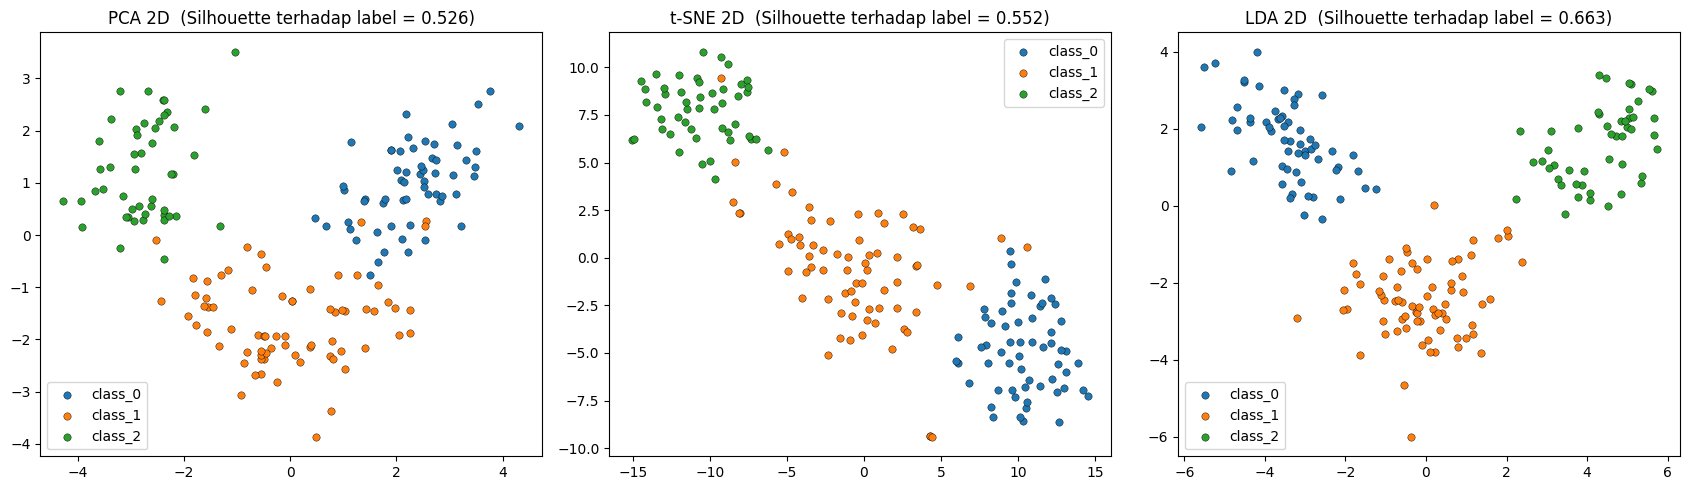

In [10]:
from sklearn.datasets import load_wine
from sklearn.metrics import silhouette_score

wine = load_wine()
Xw, yw = wine.data, wine.target
Xw_s = StandardScaler().fit_transform(Xw)
print("Dimensi data Wine:", Xw.shape, "| kelas:", [str(n) for n in wine.target_names])

emb = {
    "PCA":   PCA(n_components=2).fit_transform(Xw_s),
    "t-SNE": TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(Xw_s),
    "LDA":   LinearDiscriminantAnalysis(n_components=2).fit_transform(Xw_s, yw),
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
warna = ["#1f77b4", "#ff7f0e", "#2ca02c"]
for ax, (nama, Z) in zip(axes, emb.items()):
    for kelas, w in enumerate(warna):
        ax.scatter(Z[yw == kelas, 0], Z[yw == kelas, 1], c=w, s=28, edgecolors="k", linewidths=0.3, label=wine.target_names[kelas])
    sil = silhouette_score(Z, yw)
    ax.set_title(f"{nama} 2D  (Silhouette terhadap label = {sil:.3f})")
    ax.legend()
plt.tight_layout(); plt.show()

In [11]:
# Evaluasi kuantitatif tambahan:
# (1) Silhouette di 2D, dan (2) akurasi KNN 5-fold CV pada hasil reduksi 2D.
# PCA dan LDA dimasukkan ke dalam Pipeline agar di-fit hanya pada data latih tiap fold (tanpa kebocoran).
# t-SNE tidak memiliki transform() untuk data baru, sehingga tidak dapat dievaluasi dengan cara ini.
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

skf = StratifiedKFold(5, shuffle=True, random_state=42)
cv_pca = cross_val_score(make_pipeline(StandardScaler(), PCA(2), KNeighborsClassifier(5)), Xw, yw, cv=skf).mean()
cv_lda = cross_val_score(make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(n_components=2), KNeighborsClassifier(5)), Xw, yw, cv=skf).mean()

pd.DataFrame({
    "Metode": ["PCA", "t-SNE", "LDA"],
    "Silhouette 2D (label asli)": [round(silhouette_score(emb[m], yw), 3) for m in ["PCA", "t-SNE", "LDA"]],
    "Akurasi KNN 5-fold CV pada 2D": [round(cv_pca, 3), "tidak tersedia", round(cv_lda, 3)],
    "Memakai label?": ["Tidak (unsupervised)", "Tidak (unsupervised)", "Ya (supervised)"],
    "Bisa untuk data baru?": ["Ya", "Tidak", "Ya"],
})

,Metode,Silhouette 2D (label asli),Akurasi KNN 5-fold CV pada 2D,Memakai label?,Bisa untuk data baru?
0,PCA,0.526,0.967,Tidak (unsupervised),Ya
1,t-SNE,0.552,tidak tersedia,Tidak (unsupervised),Tidak
2,LDA,0.663,0.989,Ya (supervised),Ya


**Analisis Latihan 2:**

| Metode | Silhouette 2D (label asli) | Akurasi KNN 5-fold CV pada 2D | Memakai label? | Untuk data baru? |
|---|---|---|---|---|
| PCA | 0,526 | 0,967 | Tidak | Ya |
| t-SNE | 0,563 | tidak tersedia | Tidak | Tidak |
| LDA | **0,663** | **0,989** | Ya | Ya |

**Kualitas pemisahan kelas**
- **LDA paling baik.** Tiga kelas membentuk tiga gugus dengan tumpang tindih sangat sedikit, dan skor Silhouette tertinggi. Hal ini wajar karena LDA memakai label untuk mencari sumbu yang memaksimalkan jarak antarkelas dan meminimalkan sebaran di dalam kelas.
- **PCA** memisahkan *class_2* dengan jelas, tetapi *class_0* dan *class_1* saling bertumpuk di bagian tengah-kanan. PCA hanya mencari arah dengan variance terbesar tanpa mempertimbangkan kelas.
- **t-SNE** memberi pemisahan yang cukup baik (Silhouette 0,563, sedikit di atas PCA), tetapi batas *class_0* dan *class_1* masih bersinggungan. Pada data Wine yang sederhana, keunggulan t-SNE tidak sebesar pada Digits (Praktikum 11.6).

**Catatan penting**
1. Skor Silhouette LDA cenderung "optimistis" karena LDA melihat label saat dilatih. Karena itu ditambahkan uji yang adil: KNN dengan 5-fold CV, di mana PCA dan LDA di-fit hanya pada data latih tiap fold. LDA tetap unggul (0,989 vs 0,967), walau selisihnya ≈ 2 poin dan datanya hanya 178 sampel.
2. LDA hanya bisa menghasilkan maksimal (jumlah kelas − 1) komponen, yaitu 2 untuk Wine, sehingga tepat untuk visualisasi 2D.

**Kesimpulan:** PCA untuk reduksi tanpa label dan sebagai preprocessing; t-SNE khusus eksplorasi visual pada struktur non-linear; LDA bila label tersedia dan tujuannya klasifikasi atau pemisahan kelas.